# Learned matching

Models trained on the train labels; precision, recall and F1 on the validation labels.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110
PAIRS = ["wikidata-ror", "deqar-ror"]

In [2]:
matching = pd.read_csv("results/matching.csv")
matching[["round", "pair", "matcher", "threshold", "P", "R", "F1", "corr", "seconds"]]

,round,pair,matcher,threshold,P,R,F1,corr,seconds
0,2,wikidata-ror,logistic regression,0.45,0.951,0.978,0.964,56990,188.1
1,2,wikidata-ror,random forest,0.65,0.963,0.949,0.956,45003,190.3
2,2,wikidata-ror,gradient boosting,0.70,0.970,0.942,0.956,34187,189.1
3,2,deqar-ror,logistic regression,0.30,0.930,0.936,0.933,20569,60.1
4,2,deqar-ror,random forest,0.35,0.964,0.943,0.953,19354,60.0
5,2,deqar-ror,gradient boosting,0.35,0.984,0.879,0.929,16649,60.2
6,3,wikidata-ror,logistic regression,0.45,0.951,0.978,0.964,54702,241.6
7,3,wikidata-ror,random forest,0.55,0.931,0.978,0.954,72829,237.8
8,3,wikidata-ror,gradient boosting,0.65,0.956,0.949,0.953,34126,238.8
9,3,wikidata-ror,logistic regression + part_word,0.45,0.950,0.971,0.961,53022,262.9


In [3]:
def plot_matching(df, rnd):
    fig, axes = plt.subplots(1, 2, figsize=(12, 0.45 * df["matcher"].nunique() + 1.5), sharey=True)
    for ax, pair in zip(axes, PAIRS):
        part = df[(df["round"] == rnd) & (df["pair"] == pair)].set_index("matcher")[["P", "R", "F1"]]
        part.plot.barh(ax=ax, width=0.8, legend=False)
        ax.set_xlim(0, 1)
        ax.set_title(f"round {rnd}: {pair}")
        ax.set_ylabel("")
    fig.legend(["P", "R", "F1"], loc="upper center", ncol=3)
    plt.tight_layout(rect=(0, 0, 1, 0.93))

## Round 2

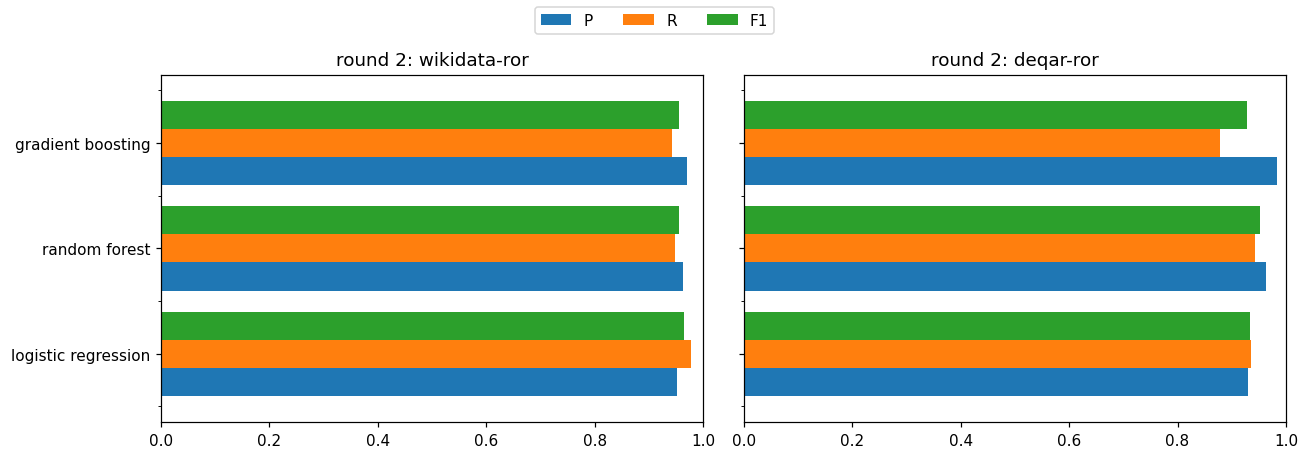

In [4]:
plot_matching(matching, 2)

## Round 3: translated names, and the extra feature part_word

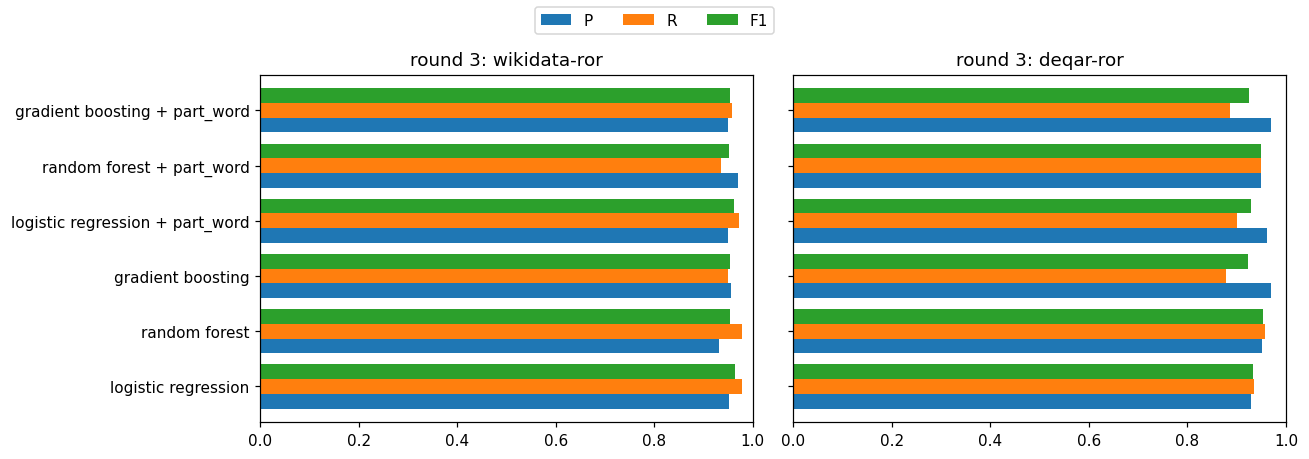

In [5]:
plot_matching(matching, 3)

## Rule-based against learned (best of each, round 2)

,method,pair,matcher,P,R,F1
25,rule-based,deqar-ror,"rule: all attributes (+ year, position)",0.939,0.872,0.904
15,rule-based,wikidata-ror,"rule: all attributes (+ year, position)",0.961,0.899,0.929
4,learned,deqar-ror,random forest,0.964,0.943,0.953
0,learned,wikidata-ror,logistic regression,0.951,0.978,0.964


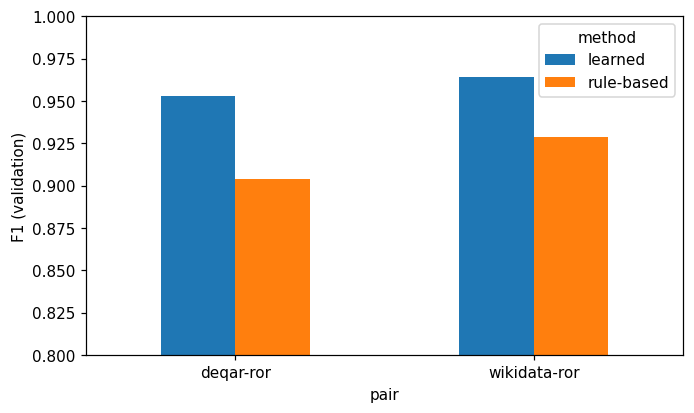

In [6]:
rules = pd.read_csv("../03_rule_based/results/matching.csv")
best = []
for name, df in [("rule-based", rules), ("learned", matching)]:
    part = df[df["round"] == 2]
    best.append(part.loc[part.groupby("pair")["F1"].idxmax()].assign(method=name))
best = pd.concat(best)
best.pivot(index="pair", columns="method", values="F1").plot.bar(rot=0, ylim=(0.8, 1), figsize=(7, 4))
plt.ylabel("F1 (validation)")
best[["method", "pair", "matcher", "P", "R", "F1"]]